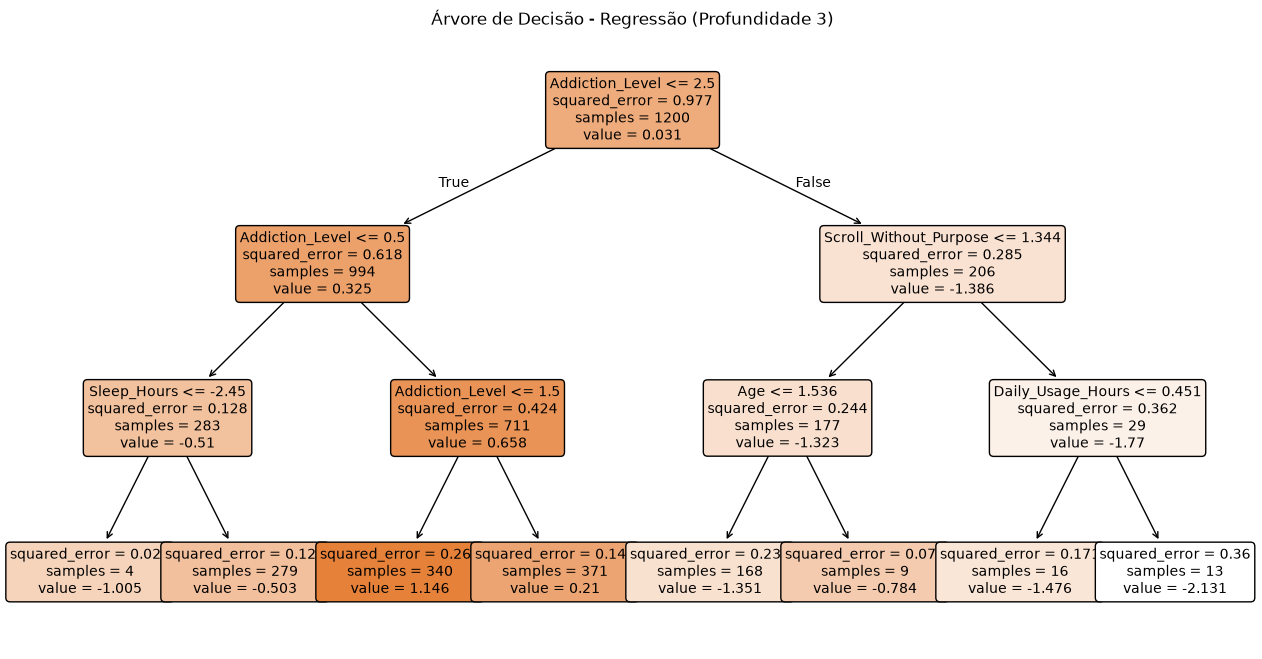

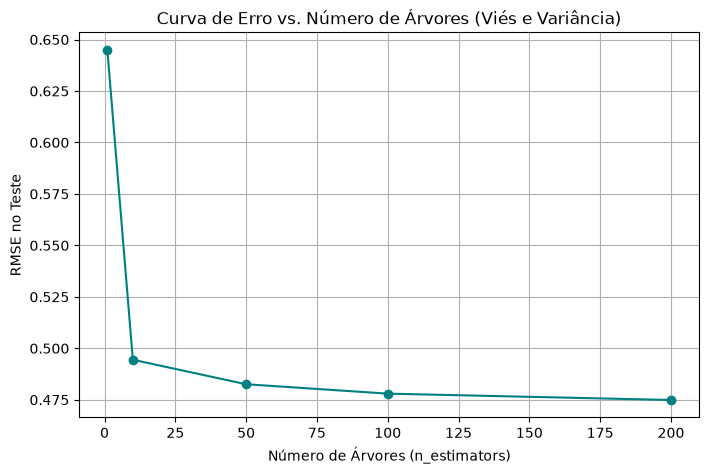

Tamanho da Árvore de Decisão (nós): 15, Folhas: 8
Tamanho do modelo Random Forest em disco: 16773.20 KB


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
import joblib
import os

train_df = pd.read_csv('../data/processed/train_regression.csv')
test_df = pd.read_csv('../data/processed/test_regression.csv')
target_col = train_df.columns[-1]
X_train, y_train = train_df.drop(columns=[target_col]), train_df[target_col]
X_test, y_test = test_df.drop(columns=[target_col]), test_df[target_col]

# 1. Visualização da Árvore de Decisão Ajustada
dt_model = DecisionTreeRegressor(max_depth=3, random_state=42)
dt_model.fit(X_train, y_train)

plt.figure(figsize=(16, 8))
plot_tree(dt_model, feature_names=X_train.columns, filled=True, rounded=True, fontsize=10)
plt.title("Árvore de Decisão - Regressão (Profundidade 3)")
plt.savefig('../reports/figures/regression_tree_plot.png', bbox_inches='tight')
plt.show()

# 2. Curva de Erro vs Número de Árvores (Random Forest)
n_estimators_list = [1, 10, 50, 100, 200]
erros_rmse = []

for n in n_estimators_list:
    rf_temp = RandomForestRegressor(n_estimators=n, random_state=42, n_jobs=-1)
    rf_temp.fit(X_train, y_train)
    preds = rf_temp.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    erros_rmse.append(rmse)

plt.figure(figsize=(8, 5))
plt.plot(n_estimators_list, erros_rmse, marker='o', linestyle='-', color='teal')
plt.xlabel("Número de Árvores (n_estimators)")
plt.ylabel("RMSE no Teste")
plt.title("Curva de Erro vs. Número de Árvores (Viés e Variância)")
plt.grid(True)
plt.savefig('../reports/figures/rf_regression_error_curve.png', bbox_inches='tight')
plt.show()

# 3. Tamanho do Modelo em Disco
model_path = '../models/rf_regression_model.pkl'
os.makedirs('../models', exist_ok=True)
joblib.dump(rf_temp, model_path)
tamanho_kb = os.path.getsize(model_path) / 1024

print(f"Tamanho da Árvore de Decisão (nós): {dt_model.tree_.node_count}, Folhas: {dt_model.tree_.n_leaves}")
print(f"Tamanho do modelo Random Forest em disco: {tamanho_kb:.2f} KB")